---
## 2. 多源栅格数据的处理和分析

**目标：**
- 掌握利用GEE下载数据（MCD12Q1.061 和 MCD12Q2.006）；
- 掌握栅格数据的裁切，以及合成多波段数据（GeoTIFF格式）；
- 掌握如何利用掩膜数据提取感兴趣的目标数据（例如，提取不同土地覆盖区域下对应的气象要素及物候数据等）。

**数据：**
- 三江源国家公园矢量边界数据；
- 研究区MCD12Q1、 MCD12Q2.006数据。

**实验要求：**
- 下载覆盖研究区的2001-2023年的MODIS MCD12Q1数据;
- 利用研究区对MCD12Q1数据裁切并合成为多波段的GeoTIFF格式数据；
- 分析研究区各土地覆盖类型区域对应的气象要素和物候（生长季长度）特征。

In [1]:
pip install rasterio geopandas fiona shapely

   ---------------------------------------- 0.0/24.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/24.5 MB ? eta -:--:--
   ---------------------------------------- 0.3/24.5 MB ? eta -:--:--
   - -------------------------------------- 0.8/24.5 MB 1.4 MB/s eta 0:00:17
   - -------------------------------------- 1.0/24.5 MB 1.3 MB/s eta 0:00:19
   - -------------------------------------- 1.0/24.5 MB 1.3 MB/s eta 0:00:19
   -- ------------------------------------- 1.3/24.5 MB 1.0 MB/s eta 0:00:23
   -- ------------------------------------- 1.6/24.5 MB 1.2 MB/s eta 0:00:20
   -- ------------------------------------- 1.6/24.5 MB 1.2 MB/s eta 0:00:20
   -- ------------------------------------- 1.8/24.5 MB 1.0 MB/s eta 0:00:22
   -- ------------------------------------- 1.8/24.5 MB 1.0 MB/s eta 0:00:22
   --- ------------------------------------ 2.1/24.5 MB 896.4 kB/s eta 0:00:25
   --- ------------------------------------ 2.1/24.5 MB 896.4 kB/s eta 0:00:25
   --- ---------

In [ ]:
#利用研究区对MCD12Q1数据裁切并合成为多波段的GeoTIFF格式数据
import os
import glob
import geopandas as gpd
import rasterio
from rasterio.mask import mask

# --- 路径配置 ---
shp_path = "./data/SanJiangYuan/boua.shp"
input_dir = "./data/MCD12Q1.061/"
output_path = "./outputs/MCD12Q1_2001_2023_Stacked.tif"

# 1. 加载研究区矢量文件并统一坐标系
gdf = gpd.read_file(shp_path)

# 2. 获取 2001-2023 年的所有 .tif 文件并排序
# 确保文件名按年份顺序排列
tif_files = sorted(glob.glob(os.path.join(input_dir, "MCD12Q1_*.tif")))
tif_files = [f for f in tif_files if 2001 <= int(os.path.basename(f).split('_')[1].split('.')[0]) <= 2023]

# 3. 准备裁剪和堆叠
clipped_data = []
out_meta = None

print(f"开始处理，共计 {len(tif_files)} 个年份的数据...")

for i, tif_path in enumerate(tif_files):
    with rasterio.open(tif_path) as src:
        # 检查坐标系是否一致，如果不一致则转换矢量坐标
        if i == 0:
            if gdf.crs != src.crs:
                gdf = gdf.to_crs(src.crs)
            
            # 获取裁剪后的元数据参考
            # 这里的 shapes 是地理对象的几何集合
            shapes = [feature["geometry"] for _, feature in gdf.iterrows()]
            
        # 执行裁剪 (Crop=True 会根据矢量外接矩形自动调整输出尺寸)
        out_image, out_transform = mask(src, shapes, crop=True)
        
        # 将裁剪后的单波段数据存入列表
        clipped_data.append(out_image[0]) # 只取第一个波段
        
        # 记录第一个文件的元数据作为输出模板
        if i == 0:
            out_meta = src.meta.copy()
            out_meta.update({
                "driver": "GTiff",
                "height": out_image.shape[1],
                "width": out_image.shape[2],
                "transform": out_transform,
                "count": len(tif_files), # 设置最终波段数为年份总数
                "nodata": src.nodata
            })
    print(f"已完成: {os.path.basename(tif_path)}")

# 4. 写入多波段 GeoTIFF
with rasterio.open(output_path, "w", **out_meta) as dest:
    for i, band_data in enumerate(clipped_data):
        dest.write(band_data, i + 1) # 波段索引从1开始
        dest.set_band_description(i + 1, f"Year_{2001 + i}")

print(f"--- 处理完成 ---")
print(f"结果已保存至: {output_path}")

开始处理，共计 23 个年份的数据...
已完成: MCD12Q1_2001.tif
已完成: MCD12Q1_2002.tif
已完成: MCD12Q1_2003.tif
已完成: MCD12Q1_2004.tif
已完成: MCD12Q1_2005.tif
已完成: MCD12Q1_2006.tif
已完成: MCD12Q1_2007.tif
已完成: MCD12Q1_2008.tif
已完成: MCD12Q1_2009.tif
已完成: MCD12Q1_2010.tif
已完成: MCD12Q1_2011.tif
已完成: MCD12Q1_2012.tif
已完成: MCD12Q1_2013.tif
已完成: MCD12Q1_2014.tif
已完成: MCD12Q1_2015.tif
已完成: MCD12Q1_2016.tif
已完成: MCD12Q1_2017.tif
已完成: MCD12Q1_2018.tif
已完成: MCD12Q1_2019.tif
已完成: MCD12Q1_2020.tif
已完成: MCD12Q1_2021.tif
已完成: MCD12Q1_2022.tif
已完成: MCD12Q1_2023.tif
--- 处理完成 ---
结果已保存至: ./outputs/MCD12Q1_2001_2023_Stacked.tif


In [4]:
# 利用研究区对MCD12Q2数据的Greenup和Dormancy波段进行裁切并合成为多波段的GeoTIFF格式数据
import os
import glob
import geopandas as gpd
import rasterio
from rasterio.mask import mask
import numpy as np

# --- 路径配置 ---
shp_path = "./data/SanJiangYuan/boua.shp"
input_dir = "./data/MCD12Q2.006/"
output_dir = "./outputs/"
os.makedirs(output_dir, exist_ok=True)

# 输出文件路径
output_greenup = os.path.join(output_dir, "MCD12Q2_Greenup_2001_2019_Stacked.tif")
output_dormancy = os.path.join(output_dir, "MCD12Q2_Dormancy_2001_2019_Stacked.tif")
output_combined = os.path.join(output_dir, "MCD12Q2_Greenup_Dormancy_2001_2019_Combined.tif")

# 1. 加载研究区矢量文件
print("正在加载研究区矢量文件...")
gdf = gpd.read_file(shp_path)
print(f"矢量文件加载成功，包含 {len(gdf)} 个要素")

# 2. 获取所有Greenup和Dormancy文件
greenup_files = sorted(glob.glob(os.path.join(input_dir, "*Greenup*.tif")))
dormancy_files = sorted(glob.glob(os.path.join(input_dir, "*Dormancy*.tif")))

# 根据年份范围过滤（2001-2024）
def extract_year_from_filename(filename):
    """从文件名中提取年份"""
    import re
    basename = os.path.basename(filename)
    # 尝试匹配4位数字年份
    year_match = re.search(r'(19|20)\d{2}', basename)
    if year_match:
        return int(year_match.group(0))
    return None

# 过滤2001-2023年的文件
greenup_files = [f for f in greenup_files if 2001 <= extract_year_from_filename(f) <= 2023]
dormancy_files = [f for f in dormancy_files if 2001 <= extract_year_from_filename(f) <= 2023]

print(f"找到 {len(greenup_files)} 个Greenup波段文件 (2001-2019)")
print(f"找到 {len(dormancy_files)} 个Dormancy波段文件 (2001-2019)")

# 确保两个列表长度一致
if len(greenup_files) != len(dormancy_files):
    print(f"警告：Greenup ({len(greenup_files)}) 和 Dormancy ({len(dormancy_files)}) 文件数量不匹配")
    min_len = min(len(greenup_files), len(dormancy_files))
    greenup_files = greenup_files[:min_len]
    dormancy_files = dormancy_files[:min_len]
    print(f"将处理前 {min_len} 个年份的数据")

def process_band_files(file_list, band_name, output_path):
    """
    处理单个波段的所有年份文件，裁剪并合成为多波段GeoTIFF
    
    Parameters:
    - file_list: 文件路径列表
    - band_name: 波段名称（用于显示）
    - output_path: 输出文件路径
    """
    print(f"\n开始处理 {band_name} 波段...")
    
    clipped_data = []
    out_meta = None
    shapes = None
    
    for i, tif_path in enumerate(file_list):
        with rasterio.open(tif_path) as src:
            # 第一次迭代时获取几何信息并转换坐标系
            if i == 0:
                if gdf.crs != src.crs:
                    print(f"将矢量数据从 {gdf.crs} 转换到 {src.crs}")
                    gdf_proj = gdf.to_crs(src.crs)
                else:
                    gdf_proj = gdf
                
                shapes = [feature["geometry"] for _, feature in gdf_proj.iterrows()]
            
            # 执行裁剪
            out_image, out_transform = mask(src, shapes, crop=True)
            
            # 存储裁剪后的数据（移除波段维度）
            clipped_data.append(out_image[0])
            
            # 记录第一个文件的元数据
            if i == 0:
                out_meta = src.meta.copy()
                out_meta.update({
                    "driver": "GTiff",
                    "height": out_image.shape[1],
                    "width": out_image.shape[2],
                    "transform": out_transform,
                    "count": len(file_list),
                    "nodata": src.nodata if src.nodata is not None else -9999,
                    "compress": "lzw"  # 添加压缩以减少文件大小
                })
        
        # 提取年份用于显示
        year = extract_year_from_filename(tif_path)
        print(f"  已完成: {year}年 - {os.path.basename(tif_path)}")
    
    # 写入多波段GeoTIFF
    print(f"正在写入 {band_name} 多波段文件...")
    with rasterio.open(output_path, "w", **out_meta) as dest:
        for i, band_data in enumerate(clipped_data):
            dest.write(band_data, i + 1)
            # 提取年份设置波段描述
            year = extract_year_from_filename(file_list[i])
            dest.set_band_description(i + 1, f"{band_name}_{year}")
    
    print(f"{band_name} 波段处理完成，保存至: {output_path}")
    return output_path

def combine_bands(greenup_path, dormancy_path, output_path):
    """
    将Greenup和Dormancy的多波段文件合并为一个文件
    
    Parameters:
    - greenup_path: Greenup多波段文件路径
    - dormancy_path: Dormancy多波段文件路径
    - output_path: 合并后的输出文件路径
    """
    print("\n开始合并Greenup和Dormancy波段...")
    
    with rasterio.open(greenup_path) as greenup_src:
        with rasterio.open(dormancy_path) as dormancy_src:
            # 检查两个文件的尺寸和变换是否一致
            if (greenup_src.height != dormancy_src.height or 
                greenup_src.width != dormancy_src.width):
                print("错误：两个文件的尺寸不一致，无法合并")
                return None
            
            # 获取元数据
            out_meta = greenup_src.meta.copy()
            total_bands = greenup_src.count + dormancy_src.count
            out_meta.update({
                "count": total_bands,
                "compress": "lzw"
            })
            
            # 创建输出文件
            with rasterio.open(output_path, "w", **out_meta) as dest:
                # 写入Greenup波段
                for i in range(1, greenup_src.count + 1):
                    band_data = greenup_src.read(i)
                    dest.write(band_data, i)
                    dest.set_band_description(i, greenup_src.descriptions[i-1])
                
                # 写入Dormancy波段
                offset = greenup_src.count
                for i in range(1, dormancy_src.count + 1):
                    band_data = dormancy_src.read(i)
                    dest.write(band_data, offset + i)
                    dest.set_band_description(offset + i, dormancy_src.descriptions[i-1])
    
    print(f"合并完成，保存至: {output_path}")
    print(f"总波段数: {total_bands} (Greenup: {greenup_src.count}, Dormancy: {dormancy_src.count})")
    return output_path

# --- 主程序执行 ---
if __name__ == "__main__":
    print("=" * 60)
    print("MCD12Q2 数据处理开始")
    print("=" * 60)
    
    # 1. 处理Greenup波段
    if greenup_files:
        process_band_files(greenup_files, "Greenup", output_greenup)
    else:
        print("未找到Greenup波段文件")
    
    # 2. 处理Dormancy波段
    if dormancy_files:
        process_band_files(dormancy_files, "Dormancy", output_dormancy)
    else:
        print("未找到Dormancy波段文件")
    
    # 3. 合并两个波段（可选）
    if os.path.exists(output_greenup) and os.path.exists(output_dormancy):
        combine_bands(output_greenup, output_dormancy, output_combined)
    
    # 4. 输出处理报告
    print("\n" + "=" * 60)
    print("--- 处理完成 ---")
    print("=" * 60)
    print(f"Greenup多波段文件: {output_greenup}")
    print(f"Dormancy多波段文件: {output_dormancy}")
    print(f"合并多波段文件: {output_combined}")
    
    # 5. 显示文件信息
    if os.path.exists(output_combined):
        with rasterio.open(output_combined) as src:
            print(f"\n合并文件信息:")
            print(f"  波段数量: {src.count}")
            print(f"  图像尺寸: {src.height} x {src.width}")
            print(f"  投影: {src.crs}")
            print(f"  数据类型: {src.dtypes[0]}")
            print(f"\n  波段列表:")
            for i in range(1, src.count + 1, 2):  # 每两年显示一次
                if i <= src.count:
                    desc = src.descriptions[i-1]
                    print(f"    波段 {i}: {desc}")

正在加载研究区矢量文件...
矢量文件加载成功，包含 54 个要素
找到 19 个Greenup波段文件 (2001-2019)
找到 19 个Dormancy波段文件 (2001-2019)
MCD12Q2 数据处理开始

开始处理 Greenup 波段...
将矢量数据从 GEOGCS["CGCS_2000",DATUM["D_2000",SPHEROID["S_2000",6378137,298.257222101004]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433],AXIS["Longitude",EAST],AXIS["Latitude",NORTH]] 转换到 EPSG:4326
  已完成: 2001年 - MCD12Q2_Greenup_2001.tif
  已完成: 2002年 - MCD12Q2_Greenup_2002.tif
  已完成: 2003年 - MCD12Q2_Greenup_2003.tif
  已完成: 2004年 - MCD12Q2_Greenup_2004.tif
  已完成: 2005年 - MCD12Q2_Greenup_2005.tif
  已完成: 2006年 - MCD12Q2_Greenup_2006.tif
  已完成: 2007年 - MCD12Q2_Greenup_2007.tif
  已完成: 2008年 - MCD12Q2_Greenup_2008.tif
  已完成: 2009年 - MCD12Q2_Greenup_2009.tif
  已完成: 2010年 - MCD12Q2_Greenup_2010.tif
  已完成: 2011年 - MCD12Q2_Greenup_2011.tif
  已完成: 2012年 - MCD12Q2_Greenup_2012.tif
  已完成: 2013年 - MCD12Q2_Greenup_2013.tif
  已完成: 2014年 - MCD12Q2_Greenup_2014.tif
  已完成: 2015年 - MCD12Q2_Greenup_2015.tif
  已完成: 2016年 - MCD12Q2_Greenup_2016.tif
  已完成: 2017年 - MCD12Q2_Gr

In [5]:
pip install seaborn rioxarray xarray

开始处理降水数据并进行空间对齐...
-> 2001 年处理完成
-> 2002 年处理完成
-> 2003 年处理完成
-> 2004 年处理完成
-> 2005 年处理完成
-> 2006 年处理完成
-> 2007 年处理完成
-> 2008 年处理完成
-> 2009 年处理完成
-> 2010 年处理完成
-> 2011 年处理完成
-> 2012 年处理完成
-> 2013 年处理完成
-> 2014 年处理完成
-> 2015 年处理完成
-> 2016 年处理完成
-> 2017 年处理完成
-> 2018 年处理完成
-> 2019 年处理完成


C:\Users\23983\AppData\Local\Temp\ipykernel_5496\962407179.py:130: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Land_Cover', y='Precipitation', data=df, palette="husl")


图表已保存至: ./outputs\Pre_vs_LC_Boxplot.png


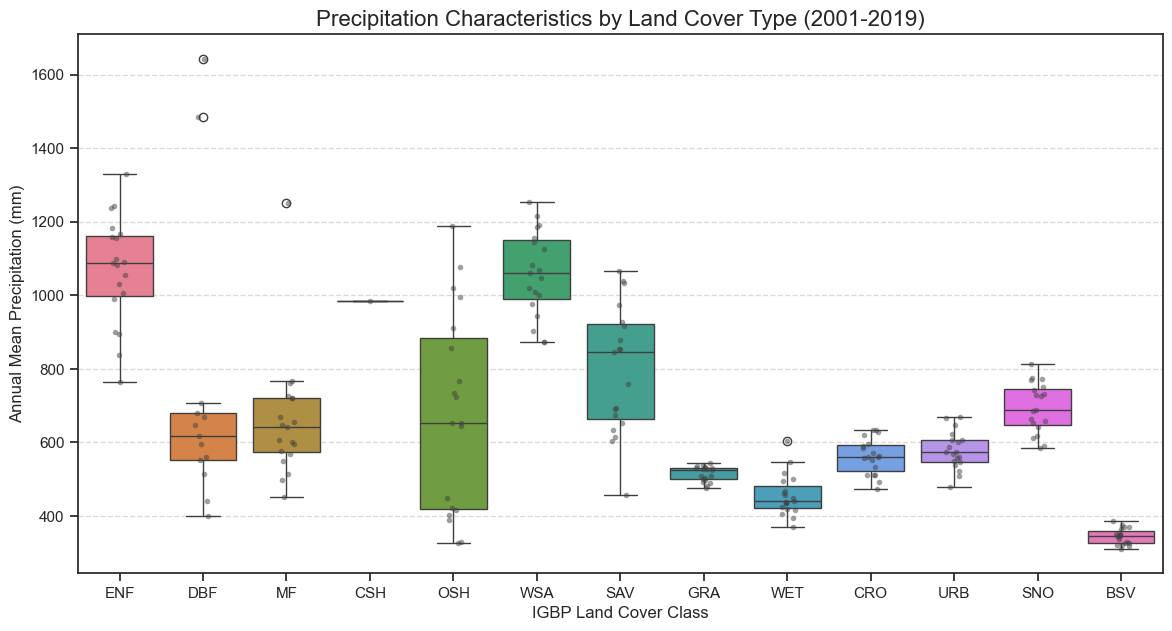

In [1]:
#研究区各土地利用类型与降水量的关系
import os
import glob
import xarray as xr
import numpy as np
import rasterio
from rasterio.enums import Resampling
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import rioxarray # 处理nc空间对齐的核心库

# ========================================================
# 1. 路径与参数配置
# ========================================================
lc_stack_path = "./outputs/MCD12Q1_2001_2023_Stacked.tif" 
pre_root_dir = "./data/Peng_climatedata/pre"
output_fig_dir = "./outputs"
years = range(2001, 2020) # 2001-2019

# 自动创建绘图保存目录
if not os.path.exists(output_fig_dir):
    os.makedirs(output_fig_dir)

# ========================================================
# 2. 读取土地利用堆栈数据 (MODIS)
# ========================================================
if not os.path.exists(lc_stack_path):
    raise FileNotFoundError(f"找不到土地利用堆栈文件: {lc_stack_path}，请确保已生成该文件。")

with rasterio.open(lc_stack_path) as src:
    lc_data = src.read()  # 维度: (波段, 高, 宽)
    lc_meta = src.meta
    lc_crs = src.crs

# ========================================================
# 3. 循环统计：降水数据与土地利用对齐
# ========================================================
all_stats = []

print("开始处理降水数据并进行空间对齐...")

for i, year in enumerate(years):
    # 路径规则：pre_root_dir/pre_20xx/pre_20xx.nc
    nc_path = os.path.join(pre_root_dir, f"pre_{year}", f"pre_{year}.nc")
    
    if not os.path.exists(nc_path):
        print(f"警告：找不到 {year} 年的 NC 文件，已跳过。路径: {nc_path}")
        continue
    
    # 使用 xarray 读取
    with xr.open_dataset(nc_path) as ds:
        # 确保变量名存在（如果你的nc变量名不是'pre'，请修改此处）
        if 'pre' not in ds.data_vars:
            print(f"错误：{year}年的NC文件中不包含变量 'pre'。可用变量: {list(ds.data_vars)}")
            continue
            
        pre_var = ds['pre']
        
        # --- 解决 MissingSpatialDimensionError ---
        # 自动重命名维度为 x 和 y 以便 rioxarray 识别
        rename_dict = {}
        for dim in ds.dims:
            if dim.lower() in ['lon', 'longitude', 'x']:
                rename_dict[dim] = 'x'
            if dim.lower() in ['lat', 'latitude', 'y']:
                rename_dict[dim] = 'y'
        
        pre_annual = pre_var.rename(rename_dict)
        
        # 如果包含时间维（如月数据），计算年均值/总和
        if 'time' in pre_annual.dims:
            # 根据数据含义选择 .sum() 或 .mean()
            pre_annual = pre_annual.mean(dim='time')
            
        # --- 空间对齐（重投影与重采样） ---
        # 假设原始nc是WGS84坐标系(EPSG:4326)
        pre_aligned = pre_annual.rio.write_crs("EPSG:4326").rio.reproject(
            lc_crs, 
            shape=(lc_meta['height'], lc_meta['width']),
            resampling=Resampling.bilinear
        )
        pre_values = pre_aligned.values
    
    # 获取当年对应的 MODIS 土地利用波段
    current_lc = lc_data[i]
    
    # 提取各土地覆盖类型的降水特征
    unique_types = np.unique(current_lc)
    for lt in unique_types:
        if lt in [0, 255]: continue # 忽略背景和填充值
        
        # 提取当前类别下的降水像素值
        type_mask = (current_lc == lt)
        valid_pre_values = pre_values[type_mask]
        
        # 剔除无效值 (NaN)
        valid_pre_values = valid_pre_values[~np.isnan(valid_pre_values)]
        
        if valid_pre_values.size > 0:
            all_stats.append({
                'Year': year,
                'Type_ID': int(lt),
                'Precipitation': np.mean(valid_pre_values)
            })
            
    print(f"-> {year} 年处理完成")

# ========================================================
# 4. 构建结果表与可视化
# ========================================================
if not all_stats:
    print("没有提取到任何有效统计数据，请检查空间重叠区域。")
else:
    df = pd.DataFrame(all_stats)

    # IGBP 土地覆盖类型映射表
    igbp_map = {
        1: 'ENF', 2: 'EBF', 3: 'DNF', 4: 'DBF', 5: 'MF', 
        6: 'CSH', 7: 'OSH', 8: 'WSA', 9: 'SAV', 10: 'GRA', 
        11: 'WET', 12: 'CRO', 13: 'URB', 14: 'CNM', 15: 'SNO', 16: 'BSV'
    }
    df['Land_Cover'] = df['Type_ID'].map(igbp_map)

    # 绘制箱线图
    plt.figure(figsize=(14, 7))
    sns.set_theme(style="ticks")
    
    # 绘制不同地类的降水分布特征
    sns.boxplot(x='Land_Cover', y='Precipitation', data=df, palette="husl")
    sns.stripplot(x='Land_Cover', y='Precipitation', data=df, color=".25", size=4, alpha=0.5)

    plt.title("Precipitation Characteristics by Land Cover Type (2001-2019)", fontsize=16)
    plt.xlabel("IGBP Land Cover Class", fontsize=12)
    plt.ylabel("Annual Mean Precipitation (mm)", fontsize=12)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    
    # 保存并显示
    save_path = os.path.join(output_fig_dir, "Pre_vs_LC_Boxplot.png")
    plt.savefig(save_path, dpi=300)
    print(f"图表已保存至: {save_path}")
    plt.show()

正在处理气温数据并匹配土地利用类型...
已完成: 2001 年统计
已完成: 2002 年统计
已完成: 2003 年统计
已完成: 2004 年统计
已完成: 2005 年统计
已完成: 2006 年统计
已完成: 2007 年统计
已完成: 2008 年统计
已完成: 2009 年统计
已完成: 2010 年统计
已完成: 2011 年统计
已完成: 2012 年统计
已完成: 2013 年统计
已完成: 2014 年统计
已完成: 2015 年统计
已完成: 2016 年统计
已完成: 2017 年统计
已完成: 2018 年统计
已完成: 2019 年统计


C:\Users\23983\AppData\Local\Temp\ipykernel_5496\2645772540.py:122: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Land_Cover', y='Temperature', data=df, palette="coolwarm", showfliers=False)


分析完成！图表已保存至: ./outputs\Temp_vs_LC_Analysis.png


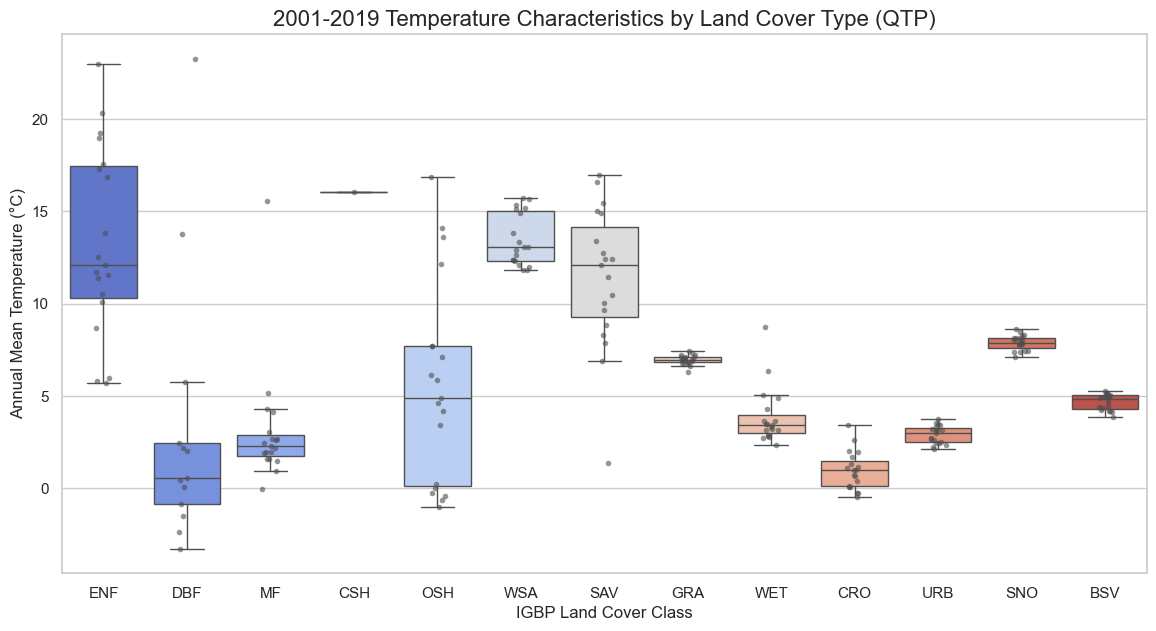

In [2]:
#研究区各土地覆盖类型区域与气温的关系
import os
import glob
import xarray as xr
import numpy as np
import rasterio
from rasterio.enums import Resampling
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import rioxarray  # 必须确保已安装：pip install rioxarray

# ========================================================
# 1. 路径与参数配置
# ========================================================
# 土地利用数据（假设已由上一步脚本生成）
lc_stack_path = "./outputs/MCD12Q1_2001_2023_Stacked.tif" 
# 气温数据根目录
tmp_root_dir = "./data/Peng_climatedata/tmp"
# 输出目录
output_fig_dir = "./outputs"
years = range(2001, 2020)  # 2001-2019

if not os.path.exists(output_fig_dir):
    os.makedirs(output_fig_dir)

# ========================================================
# 2. 读取 MODIS 土地利用数据
# ========================================================
if not os.path.exists(lc_stack_path):
    raise FileNotFoundError(f"未找到土地利用堆栈文件: {lc_stack_path}")

with rasterio.open(lc_stack_path) as src:
    lc_data = src.read()  # (bands, height, width)
    lc_meta = src.meta
    lc_crs = src.crs

# ========================================================
# 3. 循环处理与空间对齐
# ========================================================
all_stats = []

print("正在处理气温数据并匹配土地利用类型...")

for i, year in enumerate(years):
    # 匹配路径：tmp_root_dir/tmp_20xx/tmp_20xx.nc
    nc_path = os.path.join(tmp_root_dir, f"tmp_{year}", f"tmp_{year}.nc")
    
    if not os.path.exists(nc_path):
        print(f"跳过：未找到 {year} 年数据 ({nc_path})")
        continue
    
    # 读取 NC 文件
    with xr.open_dataset(nc_path) as ds:
        # 自动识别变量名 (通常为 tmp 或 t2m)
        var_name = 'tmp' if 'tmp' in ds.data_vars else list(ds.data_vars)[0]
        tmp_var = ds[var_name]
        
        # --- 解决空间维度识别问题 ---
        rename_dict = {}
        for dim in ds.dims:
            if dim.lower() in ['lon', 'longitude', 'x']: rename_dict[dim] = 'x'
            if dim.lower() in ['lat', 'latitude', 'y']: rename_dict[dim] = 'y'
        
        tmp_annual = tmp_var.rename(rename_dict)
        
        # 如果是月数据，计算年平均气温
        if 'time' in tmp_annual.dims:
            tmp_annual = tmp_annual.mean(dim='time')
            
        # --- 空间重投影与对齐 ---
        # 降水/气温 nc 数据通常为 WGS84 (EPSG:4326)
        tmp_aligned = tmp_annual.rio.write_crs("EPSG:4326").rio.reproject(
            lc_crs, 
            shape=(lc_meta['height'], lc_meta['width']),
            resampling=Resampling.bilinear
        )
        tmp_values = tmp_aligned.values * 0.1

    # 获取当年的土地利用切片
    current_lc = lc_data[i]
    
    # 按地类统计气温特征
    unique_types = np.unique(current_lc)
    for lt in unique_types:
        if lt in [0, 255]: continue  # 忽略无效值
        
        # 提取对应地类像素的气温值
        mask_tmp = tmp_values[current_lc == lt]
        valid_tmp = mask_tmp[~np.isnan(mask_tmp)]
        
        if valid_tmp.size > 0:
            all_stats.append({
                'Year': year,
                'Type_ID': int(lt),
                'Temperature': np.mean(valid_tmp)
            })
            
    print(f"已完成: {year} 年统计")

# ========================================================
# 4. 数据转换与可视化
# ========================================================
if not all_stats:
    print("未能提取到有效数据，请检查 NC 文件与影像的空间重叠情况。")
else:
    df = pd.DataFrame(all_stats)

    # IGBP 土地覆盖类型映射
    igbp_map = {
        1: 'ENF', 2: 'EBF', 3: 'DNF', 4: 'DBF', 5: 'MF', 
        6: 'CSH', 7: 'OSH', 8: 'WSA', 9: 'SAV', 10: 'GRA', 
        11: 'WET', 12: 'CRO', 13: 'URB', 14: 'CNM', 15: 'SNO', 16: 'BSV'
    }
    df['Land_Cover'] = df['Type_ID'].map(igbp_map)

    # 绘图：各土地利用类型的气温特征箱线图
    plt.figure(figsize=(14, 7))
    sns.set_theme(style="whitegrid")
    
    # 使用中性色调展示气温分布
    sns.boxplot(x='Land_Cover', y='Temperature', data=df, palette="coolwarm", showfliers=False)
    # 叠加散点展示年份波动
    sns.stripplot(x='Land_Cover', y='Temperature', data=df, color=".3", size=4, alpha=0.6)

    plt.title("2001-2019 Temperature Characteristics by Land Cover Type (QTP)", fontsize=16)
    plt.xlabel("IGBP Land Cover Class", fontsize=12)
    plt.ylabel("Annual Mean Temperature (°C)", fontsize=12)
    
    # 保存结果
    save_path = os.path.join(output_fig_dir, "Temp_vs_LC_Analysis.png")
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"分析完成！图表已保存至: {save_path}")
    plt.show()


正在读取物候数据并计算生长季长度...
已完成 2001 年统计
已完成 2002 年统计
已完成 2003 年统计
已完成 2004 年统计
已完成 2005 年统计
已完成 2006 年统计
已完成 2007 年统计
已完成 2008 年统计
已完成 2009 年统计
已完成 2010 年统计
已完成 2011 年统计
已完成 2012 年统计
已完成 2013 年统计
已完成 2014 年统计
已完成 2015 年统计
已完成 2016 年统计
已完成 2017 年统计
已完成 2018 年统计
已完成 2019 年统计


C:\Users\23983\AppData\Local\Temp\ipykernel_5496\602572892.py:83: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Land_Cover', y='LOS', data=df, palette="viridis", inner="quart")


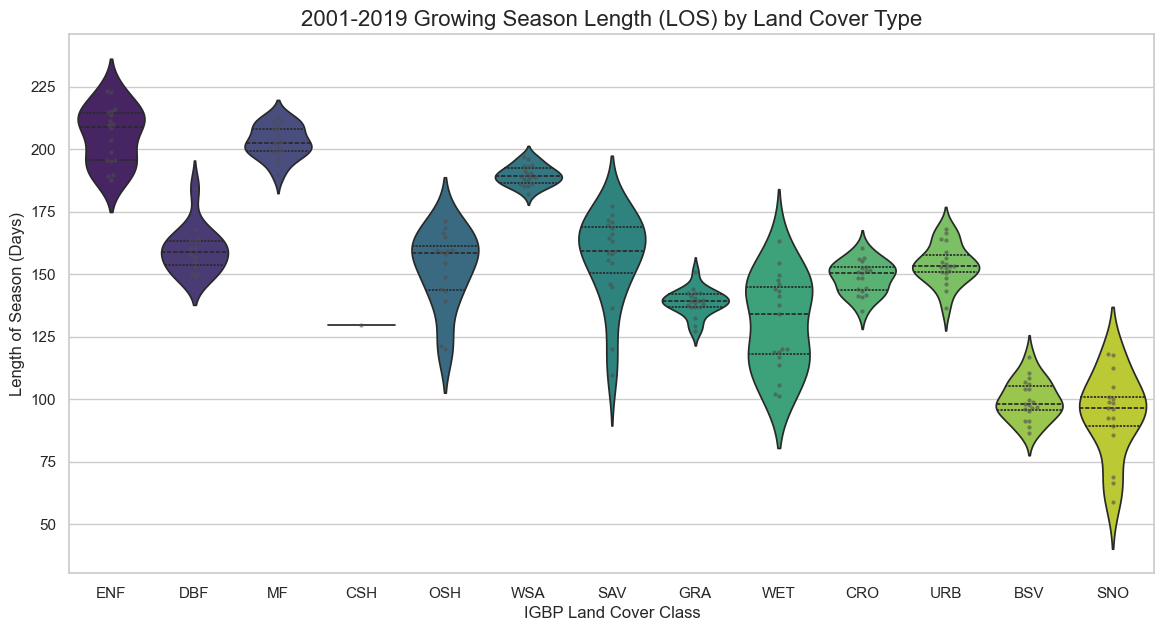

In [3]:
#研究区各土地覆盖类型与生长季的关系
import os
import rasterio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- 路径配置 ---
# 生长季参数堆栈文件
dormancy_path = "./outputs/MCD12Q2_Dormancy_2001_2019_Stacked.tif"
greenup_path = "./outputs/MCD12Q2_Greenup_2001_2019_Stacked.tif"
# 土地利用堆栈文件
lc_path = "./outputs/MCD12Q1_2001_2023_Stacked.tif" 
output_fig_dir = "./outputs"

years = range(2001, 2020) # 19年数据

# --- 1. 读取数据 ---
print("正在读取物候数据并计算生长季长度...")
with rasterio.open(dormancy_path) as ds_dorm, rasterio.open(greenup_path) as ds_green:
    # 读取所有波段 (19, height, width)
    dorm_data = ds_dorm.read().astype(float)
    green_data = ds_green.read().astype(float)
    
    # 获取元数据用于验证
    meta = ds_dorm.meta

with rasterio.open(lc_path) as ds_lc:
    # 仅读取前19个波段（2001-2019），确保与物候数据对齐
    lc_data = ds_lc.read(range(1, 20)) 

# --- 2. 计算像元级生长季长度 (LOS) ---
# 公式: Dormancy - Greenup
# 注意：MCD12Q2 的原始数值通常是自1970-01-01以来的天数
los_data = dorm_data - green_data

# 异常值处理：LOS 不可能为负数，也不太可能超过365天（单生长季假设）
los_data[(los_data <= 0) | (los_data > 365)] = np.nan

# --- 3. 按土地利用类型统计 ---
all_stats = []

for i, year in enumerate(years):
    current_los = los_data[i]
    current_lc = lc_data[i]
    
    unique_types = np.unique(current_lc)
    for lt in unique_types:
        if lt in [0, 255]: continue # 忽略无效值
        
        # 提取对应地类的生长季长度
        type_mask = (current_lc == lt)
        valid_los = current_los[type_mask]
        
        # 剔除无效值
        valid_los = valid_los[~np.isnan(valid_los)]
        
        if valid_los.size > 0:
            all_stats.append({
                'Year': year,
                'Type_ID': int(lt),
                'LOS': np.mean(valid_los)
            })
    print(f"已完成 {year} 年统计")

# --- 4. 结果可视化 ---
df = pd.DataFrame(all_stats)

# IGBP 映射
igbp_map = {
    1: 'ENF', 2: 'EBF', 3: 'DNF', 4: 'DBF', 5: 'MF', 
    6: 'CSH', 7: 'OSH', 8: 'WSA', 9: 'SAV', 10: 'GRA', 
    11: 'WET', 12: 'CRO', 13: 'URB', 14: 'CNM', 15: 'SNO', 16: 'BSV'
}
df['Land_Cover'] = df['Type_ID'].map(igbp_map)

# 绘图
plt.figure(figsize=(14, 7))
sns.set_theme(style="whitegrid")

# 小提琴图展示生长季长度分布
sns.violinplot(x='Land_Cover', y='LOS', data=df, palette="viridis", inner="quart")
# 叠加散点展示年份间差异
sns.swarmplot(x='Land_Cover', y='LOS', data=df, color="0.3", size=3, alpha=0.6)

plt.title("2001-2019 Growing Season Length (LOS) by Land Cover Type", fontsize=16)
plt.xlabel("IGBP Land Cover Class", fontsize=12)
plt.ylabel("Length of Season (Days)", fontsize=12)

# 保存
if not os.path.exists(output_fig_dir): os.makedirs(output_fig_dir)
plt.savefig(os.path.join(output_fig_dir, "LOS_Analysis.png"), dpi=300)
plt.show()